# Experiment 7: Logical and Probabilistic Reasoning
**Aim:** To implement basic Propositional Logic, First-Order Logic, and probability-based reasoning using Python.

## Exercise 1: Propositional Logic
Rule: *"If it rains, then the road is wet"*  
Logical form: R → W (equivalent to ¬R ∨ W)  
Generate the truth table and verify.

In [1]:
from itertools import product

print("Truth Table for: R -> W  (If it rains, then the road is wet)")
print("-" * 50)
print(f"{'R':<12} {'W':<12} {'R -> W':<12}")
print("-" * 50)

for R, W in product([False, True], repeat=2):
    implication = (not R) or W   # R -> W  equiv  ~R or W
    print(f"{str(R):<12} {str(W):<12} {str(implication):<12}")


Truth Table for: R -> W  (If it rains, then the road is wet)
--------------------------------------------------
R            W            R -> W      
--------------------------------------------------
False        False        True        
False        True         True        
True         False        False       
True         True         True        


## Exercise 2: First-Order Logic
Statements:
- For all x: Human(x) → Mortal(x)
- Human(Socrates)

Derive: Mortal(Socrates)

In [2]:
# Knowledge base
humans = {"Socrates", "Plato", "Aristotle"}

def is_mortal(entity):
    """All humans are mortal -- Universal instantiation."""
    return entity in humans

entity = "Socrates"

print("First-Order Logic Reasoning")
print("-" * 35)
print("Premise 1 : All humans are mortal.")
print(f"Premise 2 : {entity} is a human  ->  {entity in humans}")
print("-" * 35)
print(f"Conclusion: Is {entity} mortal?  ->  {is_mortal(entity)}")


First-Order Logic Reasoning
-----------------------------------
Premise 1 : All humans are mortal.
Premise 2 : Socrates is a human  ->  True
-----------------------------------
Conclusion: Is Socrates mortal?  ->  True


## Exercise 3: Probability of Events
Dataset: students who passed/failed and attended/did not attend class.

Calculate individual probabilities, joint probability P(A ∩ B), and union P(A ∪ B).

In [3]:
# Dataset: each row = (attended, passed)
data = [
    (True,  True),
    (True,  True),
    (True,  False),
    (True,  True),
    (False, False),
    (False, True),
    (False, False),
    (True,  True),
    (False, False),
    (True,  True),
]

n = len(data)

# Event A: student attended
A = sum(1 for attended, _ in data if attended)
# Event B: student passed
B = sum(1 for _, passed  in data if passed)
# A and B
A_and_B = sum(1 for attended, passed in data if attended and passed)

P_A       = A / n
P_B       = B / n
P_A_and_B = A_and_B / n
P_A_or_B  = P_A + P_B - P_A_and_B   # Inclusion-Exclusion

print(f"Total students          : {n}")
print(f"P(Attended)             : {P_A:.2f}")
print(f"P(Passed)               : {P_B:.2f}")
print(f"P(Attended and Passed)  : {P_A_and_B:.2f}")
print(f"P(Attended or  Passed)  : {P_A_or_B:.2f}")


Total students          : 10
P(Attended)             : 0.60
P(Passed)               : 0.60
P(Attended and Passed)  : 0.50
P(Attended or  Passed)  : 0.70


## Exercise 4: Conditional Probability
Using the same dataset, calculate:
- P(Passed | Attended) → P(B | A)
- P(Attended | Passed) → P(A | B)

In [4]:
# P(B | A) = P(A and B) / P(A)
P_B_given_A = P_A_and_B / P_A

# P(A | B) = P(A and B) / P(B)
P_A_given_B = P_A_and_B / P_B

print("Conditional Probabilities")
print("-" * 45)
print(f"P(Passed   | Attended) = {P_B_given_A:.4f}")
print(f"P(Attended | Passed  ) = {P_A_given_B:.4f}")


Conditional Probabilities
---------------------------------------------
P(Passed   | Attended) = 0.8333
P(Attended | Passed  ) = 0.8333


## Exercise 5: Bayes' Theorem — Disease Diagnosis
Given:
- P(Disease)            = 0.01  (prior)
- P(+Test | Disease)    = 0.95  (sensitivity)
- P(+Test | No Disease) = 0.05  (false positive rate)

Find: P(Disease | +Test)

In [5]:
P_disease              = 0.01
P_no_disease           = 1 - P_disease
P_pos_given_disease    = 0.95   # sensitivity
P_pos_given_no_disease = 0.05   # false positive rate

# Total probability of positive test
P_positive = (P_pos_given_disease    * P_disease
            + P_pos_given_no_disease  * P_no_disease)

# Bayes' Theorem
P_disease_given_pos = (P_pos_given_disease * P_disease) / P_positive

print("Bayes' Theorem -- Disease Diagnosis")
print("-" * 45)
print(f"P(Disease)             = {P_disease}")
print(f"P(+Test | Disease)     = {P_pos_given_disease}")
print(f"P(+Test | No Disease)  = {P_pos_given_no_disease}")
print(f"P(+Test)               = {P_positive:.4f}")
print("-" * 45)
print(f"P(Disease | +Test)     = {P_disease_given_pos:.4f}")


Bayes' Theorem -- Disease Diagnosis
---------------------------------------------
P(Disease)             = 0.01
P(+Test | Disease)     = 0.95
P(+Test | No Disease)  = 0.05
P(+Test)               = 0.0590
---------------------------------------------
P(Disease | +Test)     = 0.1610


## Exercise 6: Visualization
Bar chart of event probabilities and a line plot showing how the Bayes' posterior changes
as the disease prior varies (original vs modified sensitivity).

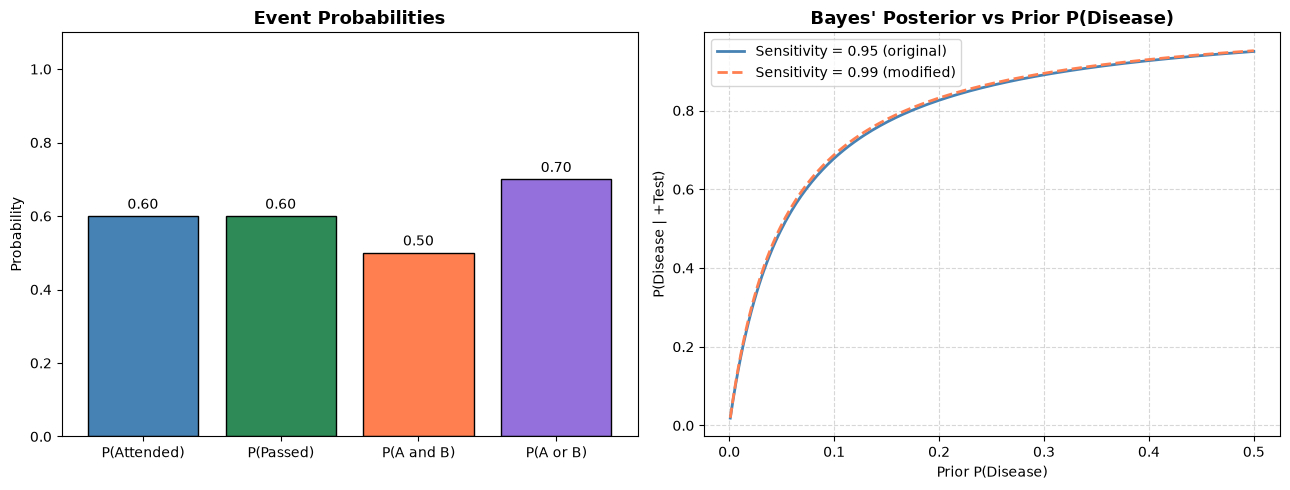

Plot saved as lab7_probabilities.png


In [6]:
import matplotlib.pyplot as plt
import numpy as np

# --- Plot 1: Bar chart of event probabilities ---
labels = ["P(Attended)", "P(Passed)", "P(A and B)", "P(A or B)"]
values = [P_A, P_B, P_A_and_B, P_A_or_B]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(labels, values,
                   color=["steelblue", "seagreen", "coral", "mediumpurple"],
                   edgecolor="black")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Event Probabilities", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Probability")
for bar, val in zip(bars, values):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.02,
                 f"{val:.2f}", ha="center", fontsize=10)

# --- Plot 2: Bayes posterior vs varying prior P(Disease) ---
priors = np.linspace(0.001, 0.5, 200)
posteriors_original = []
posteriors_modified  = []

for prior in priors:
    # Original: sensitivity = 0.95
    p_pos = 0.95 * prior + 0.05 * (1 - prior)
    posteriors_original.append(0.95 * prior / p_pos)
    # Modified: sensitivity increased to 0.99
    p_pos_mod = 0.99 * prior + 0.05 * (1 - prior)
    posteriors_modified.append(0.99 * prior / p_pos_mod)

axes[1].plot(priors, posteriors_original,
             label="Sensitivity = 0.95 (original)",
             color="steelblue", linewidth=2)
axes[1].plot(priors, posteriors_modified,
             label="Sensitivity = 0.99 (modified)",
             color="coral", linewidth=2, linestyle="--")
axes[1].set_title("Bayes' Posterior vs Prior P(Disease)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Prior P(Disease)")
axes[1].set_ylabel("P(Disease | +Test)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("lab7_probabilities.png", dpi=120)
plt.show()
print("Plot saved as lab7_probabilities.png")
